In [ ]:
!nvidia-smi

Sat Aug 29 08:44:13 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   35C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import sys

print(sys.version)

3.13.15 (main, Aug  6 2026, 11:06:23) [GCC 11.4.0]


In [ ]:
!pip install torch torchvision torchaudio

In [ ]:
!pip install torch-geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 35.1 MB/s eta 0:00:00


In [ ]:
!pip install pandas numpy matplotlib scipy scikit-learn PyWavelets

In [ ]:
import torch

print(torch.__version__)

print("GPU Available:",
      torch.cuda.is_available())

2.11.0+cu128
GPU Available: True


In [ ]:
!git clone https://github.com/STGTraffic/HSTGNN.git

Cloning into 'HSTGNN'...
remote: Enumerating objects: 539, done.
remote: Counting objects: 100% (40/40), done.
remote: Compressing objects: 100% (32/32), done.
remote: Total 539 (delta 24), reused 8 (delta 8), pack-reused 499 (from 1)
Receiving objects: 100% (539/539), 164.87 MiB | 17.40 MiB/s, done.
Resolving deltas: 100% (252/252), done.


In [ ]:
%cd HSTGNN

/content/HSTGNN


In [ ]:
!ls

data  data_pre.py  model.py  ranger21.py  README.md  test.py  train.py	util.py


In [ ]:
!find . -name "*.py"

./util.py
./ranger21.py
./train.py
./model.py
./test.py
./data_pre.py


In [ ]:
!ls data

PEMS08	Urban


In [ ]:
!python data_pre.py

Generating training data
df (17856, 170)
x shape:  (17833, 12, 170, 3) , y shape:  (17833, 12, 170, 3)
train x:  (12483, 12, 170, 3) y: (12483, 12, 170, 3)
val x:  (1783, 12, 170, 3) y: (1783, 12, 170, 3)
test x:  (3567, 12, 170, 3) y: (3567, 12, 170, 3)


In [ ]:
!sed -i 's/default=500/default=50/' train.py

In [ ]:
!grep -n "epochs" train.py

24:parser.add_argument("--epochs", type=int, default=50, help="")
136:    epochs_since_best_mae = 0
164:    for i in range(1, args.epochs + 1):
265:                epochs_since_best_mae = 0
325:                    epochs_since_best_mae = 0
331:                    epochs_since_best_mae += 1
335:            epochs_since_best_mae += 1
340:        if epochs_since_best_mae >= args.es_patience and i >= 300:


In [ ]:
!python train.py

Perform shuffle on the dataset
Namespace(device='cuda:0', data='data//PEMS08', input_dim=3, batch_size=64, learning_rate=0.001, dropout=0.1, weight_decay=0.0001, epochs=50, print_every=50, save='./logs/2026-08-29-08:45:34-', expid=1, es_patience=100)
Ranger optimizer loaded. 
Gradient Centralization usage = True
GC applied to both conv and fc layers
The number of parameters: 511057
HSTGNN(
  (Temb): TemporalEmbedding()
  (start_conv_l): Conv2d(3, 48, kernel_size=(1, 1), stride=(1, 1))
  (start_conv_h): Conv2d(3, 48, kernel_size=(1, 1), stride=(1, 1))
  (start_conv): Conv2d(3, 48, kernel_size=(1, 1), stride=(1, 1))
  (mlp): Sequential(
    (0): MultiLayerPerceptron(
      (fc1): Conv2d(48, 48, kernel_size=(1, 1), stride=(1, 1))
      (fc2): Conv2d(48, 48, kernel_size=(1, 1), stride=(1, 1))
      (act): ReLU()
      (drop): Dropout(p=0.15, inplace=False)
    )
    (1): MultiLayerPerceptron(
      (fc1): Conv2d(48, 48, kernel_size=(1, 1), stride=(1, 1))
      (fc2): Conv2d(48, 48, kernel_

In [ ]:
import pandas as pd

baseline_results = {
    "Model": ["HSTGNN"],
    "Dataset": ["PEMS08"],
    "MAE": [14.3300],
    "RMSE": [23.2007],
    "MAPE": [0.1024],
    "WMAPE": [0.0617]
}

df = pd.DataFrame(baseline_results)

df

,Model,Dataset,MAE,RMSE,MAPE,WMAPE
0,HSTGNN,PEMS08,14.33,23.2007,0.1024,0.0617


In [ ]:
df.to_csv("baseline_HSTGNN_results.csv", index=False)

In [ ]:
!ls data/PEMS08

PEMS08.npz  test.npz  train.npz  val.npz


In [ ]:
import os

for file in os.listdir("data/PEMS08"):
    print(file)

PEMS08.npz
test.npz
val.npz
train.npz


In [ ]:
import numpy as np

# Load training dataset
data = np.load("data/PEMS08/train.npz")

print("Files inside train.npz:")
print(data.files)

for key in data.files:
    print("\nVariable:", key)
    print("Shape:", data[key].shape)
    print("Data type:", data[key].dtype)

Files inside train.npz:
['x', 'y', 'x_offsets', 'y_offsets']

Variable: x
Shape: (12483, 12, 170, 3)
Data type: float64

Variable: y
Shape: (12483, 12, 170, 3)
Data type: float64

Variable: x_offsets
Shape: (12, 1)
Data type: int64

Variable: y_offsets
Shape: (12, 1)
Data type: int64


In [ ]:
import numpy as np

data = np.load("data/PEMS08/train.npz")

x = data["x"]

print("Minimum values:")
print(x.min(axis=(0,1,2)))

print("\nMaximum values:")
print(x.max(axis=(0,1,2)))

print("\nMean values:")
print(x.mean(axis=(0,1,2)))

Minimum values:
[0. 0. 0.]

Maximum values:
[1.14700000e+03 9.96527778e-01 6.00000000e+00]

Mean values:
[230.23550955   0.49581306   2.9153649 ]


In [ ]:
import numpy as np
import os

# Dataset locations
input_folder = "data/PEMS08"
output_folder = "data/PEMS08_HETEROGENEOUS"

# Create new folder
os.makedirs(output_folder, exist_ok=True)


def add_two_wheeler_feature(input_file, output_file):

    data = np.load(input_file)

    x = data["x"]
    y = data["y"]

    # Create synthetic two-wheeler ratio feature
    samples, time_steps, nodes, _ = x.shape

    # Base relationship:
    # higher traffic flow -> slightly higher two-wheeler presence
    flow = x[:, :, :, 0]

    flow_norm = (
        flow - flow.min()
    ) / (
        flow.max() - flow.min()
    )

    # two-wheeler ratio between 0.15 and 0.60
    two_wheeler_ratio = (
        0.15 +
        0.45 * flow_norm
    )

    # Add small random variation
    noise = np.random.normal(
        0,
        0.02,
        two_wheeler_ratio.shape
    )

    two_wheeler_ratio = two_wheeler_ratio + noise


    # Keep values between 0 and 1
    two_wheeler_ratio = np.clip(
        two_wheeler_ratio,
        0,
        1
    )


    # Expand dimension
    two_wheeler_ratio = np.expand_dims(
        two_wheeler_ratio,
        axis=-1
    )


    # Add new feature
    x_new = np.concatenate(
        [
            x,
            two_wheeler_ratio
        ],
        axis=-1
    )


    # Save
    np.savez(
        output_file,
        x=x_new,
        y=y,
        x_offsets=data["x_offsets"],
        y_offsets=data["y_offsets"]
    )


    print(input_file)
    print("Old shape:", x.shape)
    print("New shape:", x_new.shape)


# Process train, validation and test

for filename in ["train.npz", "val.npz", "test.npz"]:

    add_two_wheeler_feature(
        f"{input_folder}/{filename}",
        f"{output_folder}/{filename}"
    )

data/PEMS08/train.npz
Old shape: (12483, 12, 170, 3)
New shape: (12483, 12, 170, 4)
data/PEMS08/val.npz
Old shape: (1783, 12, 170, 3)
New shape: (1783, 12, 170, 4)
data/PEMS08/test.npz
Old shape: (3567, 12, 170, 3)
New shape: (3567, 12, 170, 4)


In [ ]:
!cp train.py train_original.py
!cp model.py model_original.py

In [ ]:
!grep -n "data/" train.py

115:        args.data = "data//" + args.data
121:        args.data = "data//" + args.data


In [ ]:
!grep -n "input_dim" train.py

17:parser.add_argument("--input_dim", type=int, default=3, help="number of input_dim")
47:        input_dim,
57:            device, input_dim, num_nodes, channels, granularity, dropout
152:        args.input_dim,


In [ ]:
default=4

In [ ]:
!sed -i 's/default=3/default=4/' train.py

In [ ]:
!grep -n "input_dim" train.py

17:parser.add_argument("--input_dim", type=int, default=4, help="number of input_dim")
47:        input_dim,
57:            device, input_dim, num_nodes, channels, granularity, dropout
152:        args.input_dim,


In [ ]:
!grep -n "PEMS08" train.py

16:parser.add_argument("--data", type=str, default="PEMS08", help="data path")
114:    if args.data == "PEMS08":


In [ ]:
!sed -i 's/PEMS08/PEMS08_HETEROGENEOUS/g' train.py

In [ ]:
!grep -n "PEMS08" train.py

16:parser.add_argument("--data", type=str, default="PEMS08_HETEROGENEOUS", help="data path")
114:    if args.data == "PEMS08_HETEROGENEOUS":


In [ ]:
!cp train.py train_original.py
!cp model.py model_original.py

In [ ]:
!grep -n "input_dim" train.py

17:parser.add_argument("--input_dim", type=int, default=4, help="number of input_dim")
47:        input_dim,
57:            device, input_dim, num_nodes, channels, granularity, dropout
152:        args.input_dim,


In [ ]:
!ls data/PEMS08_HETEROGENEOUS

test.npz  train.npz  val.npz


In [ ]:
import numpy as np

data = np.load("data/PEMS08_HETEROGENEOUS/train.npz")

x = data["x"]

print("Dataset shape:", x.shape)
print("Input features:", x.shape[-1])

Dataset shape: (12483, 12, 170, 4)
Input features: 4


In [ ]:
!python train.py

Perform shuffle on the dataset
Namespace(device='cuda:0', data='data//PEMS08_HETEROGENEOUS', input_dim=4, batch_size=64, learning_rate=0.001, dropout=0.1, weight_decay=0.0001, epochs=50, print_every=50, save='./logs/2026-08-29-09:52:21-', expid=1, es_patience=100)
Ranger optimizer loaded. 
Gradient Centralization usage = True
GC applied to both conv and fc layers
The number of parameters: 511201
HSTGNN(
  (Temb): TemporalEmbedding()
  (start_conv_l): Conv2d(4, 48, kernel_size=(1, 1), stride=(1, 1))
  (start_conv_h): Conv2d(4, 48, kernel_size=(1, 1), stride=(1, 1))
  (start_conv): Conv2d(4, 48, kernel_size=(1, 1), stride=(1, 1))
  (mlp): Sequential(
    (0): MultiLayerPerceptron(
      (fc1): Conv2d(48, 48, kernel_size=(1, 1), stride=(1, 1))
      (fc2): Conv2d(48, 48, kernel_size=(1, 1), stride=(1, 1))
      (act): ReLU()
      (drop): Dropout(p=0.15, inplace=False)
    )
    (1): MultiLayerPerceptron(
      (fc1): Conv2d(48, 48, kernel_size=(1, 1), stride=(1, 1))
      (fc2): Conv2d(4

In [ ]:
import pandas as pd

# Original HSTGNN results
baseline = {
    "Model": "Original HSTGNN",
    "Input Features": 3,
    "MAE": 14.3300,
    "RMSE": 23.2007,
    "MAPE": 0.1024,
    "WMAPE": 0.0617
}

# Heterogeneous HSTGNN results
heterogeneous = {
    "Model": "Heterogeneous HSTGNN",
    "Input Features": 4,
    "MAE": 14.3466,
    "RMSE": 23.4144,
    "MAPE": 0.0966,
    "WMAPE": 0.0618
}

# Create comparison table
comparison = pd.DataFrame([baseline, heterogeneous])

print("MODEL PERFORMANCE COMPARISON")
display(comparison)

# Calculate percentage change
improvement = {
    "MAE change (%)": ((baseline["MAE"] - heterogeneous["MAE"]) / baseline["MAE"]) * 100,
    "RMSE change (%)": ((baseline["RMSE"] - heterogeneous["RMSE"]) / baseline["RMSE"]) * 100,
    "MAPE change (%)": ((baseline["MAPE"] - heterogeneous["MAPE"]) / baseline["MAPE"]) * 100,
    "WMAPE change (%)": ((baseline["WMAPE"] - heterogeneous["WMAPE"]) / baseline["WMAPE"]) * 100
}

print("\nPERFORMANCE CHANGE")
for metric, value in improvement.items():
    print(f"{metric}: {value:.2f}%")

# Save comparison
comparison.to_csv("HSTGNN_model_comparison.csv", index=False)

MODEL PERFORMANCE COMPARISON


,Model,Input Features,MAE,RMSE,MAPE,WMAPE
0,Original HSTGNN,3,14.3300,23.2007,0.1024,0.0617
1,Heterogeneous HSTGNN,4,14.3466,23.4144,0.0966,0.0618



PERFORMANCE CHANGE
MAE change (%): -0.12%
RMSE change (%): -0.92%
MAPE change (%): 5.66%
WMAPE change (%): -0.16%


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Heterogeneous HSTGNN test results for each forecasting horizon
horizon_results = {
    "Horizon": list(range(1, 13)),
    "MAE": [
        12.6907, 13.1969, 13.5296, 13.8077,
        14.0837, 14.3209, 14.5914, 14.7057,
        14.9302, 15.0555, 15.4019, 15.8447
    ],
    "RMSE": [
        19.9912, 21.1049, 21.8458, 22.5465,
        23.0635, 23.4791, 23.8783, 24.1927,
        24.6213, 24.9132, 25.4048, 25.9318
    ],
    "MAPE": [
        0.0846, 0.0871, 0.0896, 0.0905,
        0.0943, 0.0967, 0.0995, 0.0980,
        0.1004, 0.1021, 0.1050, 0.1110
    ],
    "WMAPE": [
        0.0546, 0.0568, 0.0582, 0.0594,
        0.0606, 0.0617, 0.0629, 0.0634,
        0.0644, 0.0649, 0.0664, 0.0684
    ]
}

horizon_df = pd.DataFrame(horizon_results)

print("HETEROGENEOUS HSTGNN — 12-HORIZON TEST RESULTS")
display(horizon_df)

# Save results
horizon_df.to_csv(
    "HSTGNN_heterogeneous_12_horizon_results.csv",
    index=False
)

print("\nResults saved successfully.")

HETEROGENEOUS HSTGNN — 12-HORIZON TEST RESULTS


,Horizon,MAE,RMSE,MAPE,WMAPE
0,1,12.6907,19.9912,0.0846,0.0546
1,2,13.1969,21.1049,0.0871,0.0568
2,3,13.5296,21.8458,0.0896,0.0582
3,4,13.8077,22.5465,0.0905,0.0594
4,5,14.0837,23.0635,0.0943,0.0606
5,6,14.3209,23.4791,0.0967,0.0617
6,7,14.5914,23.8783,0.0995,0.0629
7,8,14.7057,24.1927,0.0980,0.0634
8,9,14.9302,24.6213,0.1004,0.0644
9,10,15.0555,24.9132,0.1021,0.0649



Results saved successfully.


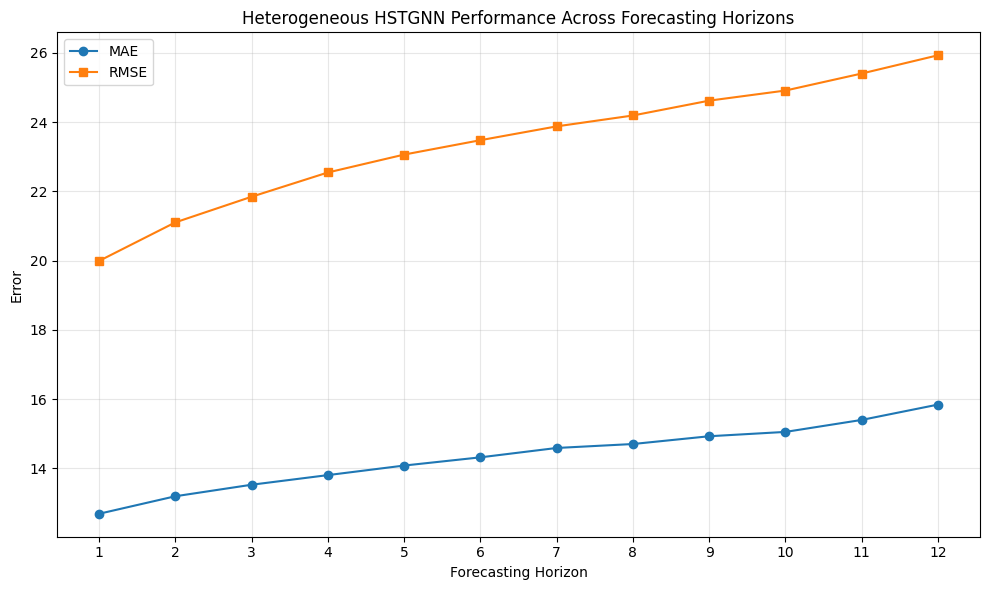

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    horizon_df["Horizon"],
    horizon_df["MAE"],
    marker="o",
    label="MAE"
)

plt.plot(
    horizon_df["Horizon"],
    horizon_df["RMSE"],
    marker="s",
    label="RMSE"
)

plt.xlabel("Forecasting Horizon")
plt.ylabel("Error")
plt.title("Heterogeneous HSTGNN Performance Across Forecasting Horizons")
plt.xticks(range(1, 13))
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    "HSTGNN_heterogeneous_horizon_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

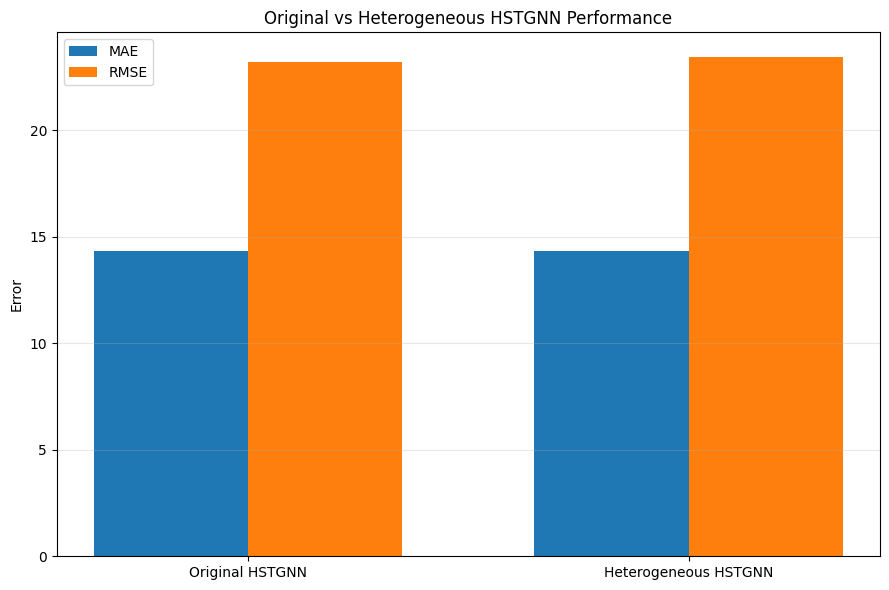

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Model comparison data
models = ["Original HSTGNN", "Heterogeneous HSTGNN"]

mae = [14.3300, 14.3466]
rmse = [23.2007, 23.4144]
mape = [0.1024, 0.0966]
wmape = [0.0617, 0.0618]

x = np.arange(len(models))
width = 0.35

# MAE and RMSE comparison
plt.figure(figsize=(9, 6))

plt.bar(x - width/2, mae, width, label="MAE")
plt.bar(x + width/2, rmse, width, label="RMSE")

plt.xticks(x, models)
plt.ylabel("Error")
plt.title("Original vs Heterogeneous HSTGNN Performance")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "HSTGNN_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

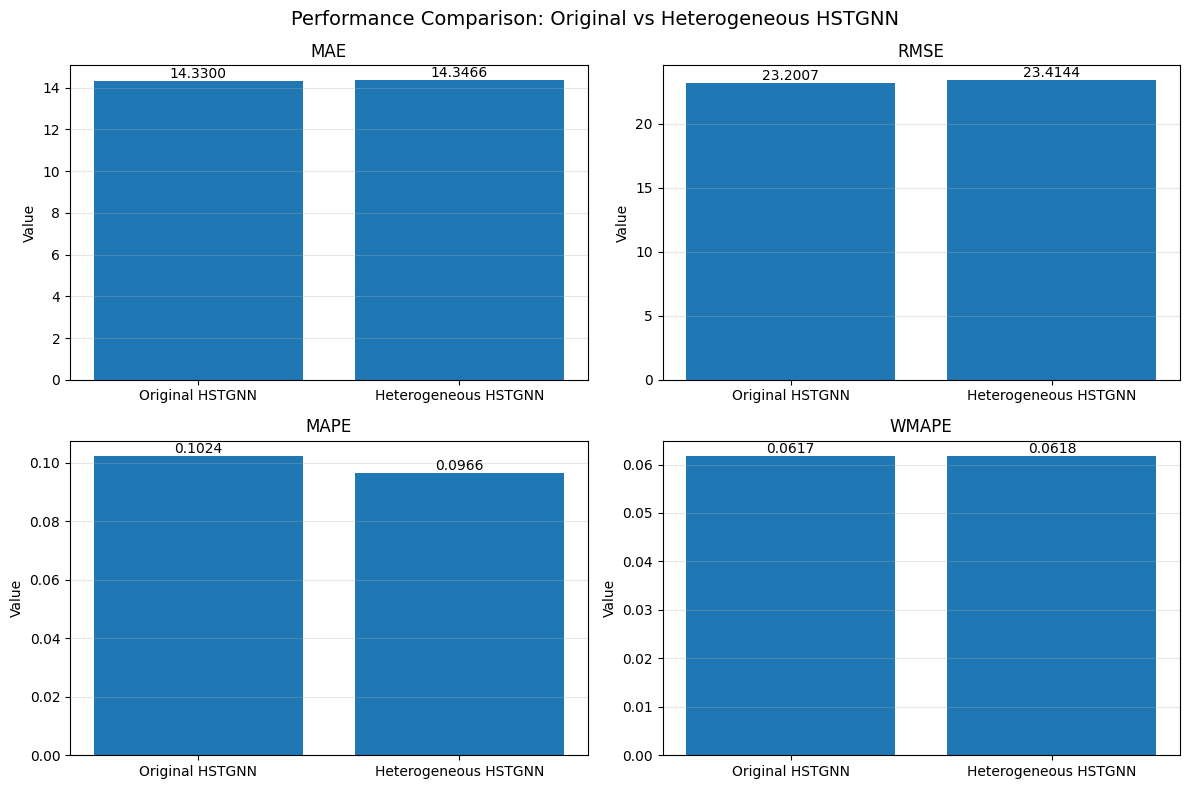

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

models = ["Original HSTGNN", "Heterogeneous HSTGNN"]

mae = [14.3300, 14.3466]
rmse = [23.2007, 23.4144]
mape = [0.1024, 0.0966]
wmape = [0.0617, 0.0618]

metrics = ["MAE", "RMSE", "MAPE", "WMAPE"]
values = [mae, rmse, mape, wmape]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, metric, data in zip(axes.flat, metrics, values):
    x = np.arange(len(models))

    ax.bar(x, data)
    ax.set_xticks(x)
    ax.set_xticklabels(models)
    ax.set_title(metric)
    ax.set_ylabel("Value")
    ax.grid(axis="y", alpha=0.3)

    for i, value in enumerate(data):
        ax.text(
            i,
            value,
            f"{value:.4f}",
            ha="center",
            va="bottom"
        )

fig.suptitle(
    "Performance Comparison: Original vs Heterogeneous HSTGNN",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "HSTGNN_final_metric_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
import pandas as pd

# Final model comparison results
final_results = pd.DataFrame({
    "Model": [
        "Original HSTGNN",
        "Heterogeneous HSTGNN"
    ],
    "Input Features": [
        3,
        4
    ],
    "MAE": [
        14.3300,
        14.3466
    ],
    "RMSE": [
        23.2007,
        23.4144
    ],
    "MAPE": [
        0.1024,
        0.0966
    ],
    "WMAPE": [
        0.0617,
        0.0618
    ]
})

# Save results
final_results.to_csv(
    "HSTGNN_final_model_comparison.csv",
    index=False
)

# Display
final_results

,Model,Input Features,MAE,RMSE,MAPE,WMAPE
0,Original HSTGNN,3,14.3300,23.2007,0.1024,0.0617
1,Heterogeneous HSTGNN,4,14.3466,23.4144,0.0966,0.0618


In [ ]:
!ls -lh HSTGNN_final_model_comparison.csv

-rw-r--r-- 1 root root 140 Aug 29 10:59 HSTGNN_final_model_comparison.csv


In [ ]:
import os

print("===== HSTGNN PRACTICAL OUTPUT CHECK =====")

files_to_check = [
    "HSTGNN_final_model_comparison.csv",
    "HSTGNN_final_metric_comparison.png",
    "HSTGNN_model_comparison.png",
    "HSTGNN_heterogeneous_horizon_performance.png",
    "baseline_HSTGNN_results.csv"
]

for file in files_to_check:
    if os.path.exists(file):
        size = os.path.getsize(file)
        print(f"✓ {file}  ({size:,} bytes)")
    else:
        print(f"✗ {file}  NOT FOUND")

print("\n===== DATASET CHECK =====")

dataset_files = [
    "data/PEMS08_HETEROGENEOUS/train.npz",
    "data/PEMS08_HETEROGENEOUS/val.npz",
    "data/PEMS08_HETEROGENEOUS/test.npz"
]

for file in dataset_files:
    if os.path.exists(file):
        print(f"✓ {file}")
    else:
        print(f"✗ {file}  NOT FOUND")

===== HSTGNN PRACTICAL OUTPUT CHECK =====
✓ HSTGNN_final_model_comparison.csv  (140 bytes)
✓ HSTGNN_final_metric_comparison.png  (210,267 bytes)
✓ HSTGNN_model_comparison.png  (76,320 bytes)
✓ HSTGNN_heterogeneous_horizon_performance.png  (135,553 bytes)
✓ baseline_HSTGNN_results.csv  (76 bytes)

===== DATASET CHECK =====
✓ data/PEMS08_HETEROGENEOUS/train.npz
✓ data/PEMS08_HETEROGENEOUS/val.npz
✓ data/PEMS08_HETEROGENEOUS/test.npz
